# Poda Alfa-Beta en un árbol

 La lista del árbol puede configurarse en la segunda celda de código.

- Un valor entero es una hoja
- Una lista representa un nodo con hijos
- El nodo raíz es un máximo
- Los niveles alternan máximo y mínimo

In [37]:
import random
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import Patch

# Genera un árbol aleatorio como lista de listas con un máximo de 5 niveles y 50 nodos hoja.
def generate_random_list_tree(levels, leaf_nodes, min_value=-10, max_value=10, seed=None):
    if not 1 <= levels <= 5:
        raise ValueError('levels debe estar entre 1 y 5.')
    if not 1 <= leaf_nodes <= 50:
        raise ValueError('leaf_nodes debe estar entre 1 y 50.')

    rng = random.Random(seed)

    if levels == 1:
        return [rng.randint(min_value, max_value) for _ in range(leaf_nodes)]

    branch_count = min(5, max(2, leaf_nodes))
    base, remainder = divmod(leaf_nodes, branch_count)
    counts = [base + (1 if i < remainder else 0) for i in range(branch_count)]
    counts = [count for count in counts if count > 0]

    children = []
    for count in counts:
        if levels == 2:
            children.append([rng.randint(min_value, max_value) for _ in range(count)])
        else:
            next_seed = rng.randint(0, 10**9)
            children.append(generate_random_list_tree(levels - 1, count, min_value, max_value, next_seed))
    return children

# Ejemplo 
#tree = [[5, 2, -5], [-6, -4], [6, -3, 1]]

#TREE_SEED = None
tree = generate_random_list_tree(levels=3, leaf_nodes=9, min_value=-10, max_value=10, seed=None)


Valor minimax con poda alfa-beta: -6.0
Ruta óptima de decisión: (0, 1, 0)
Ramas podadas:
  - Nodo: (1, 1) | motivo: corte por alfa
  - Nodo: (1, 1, 0) | motivo: corte por alfa
  - Nodo: (3, 1) | motivo: corte por alfa
  - Nodo: (3, 1, 0) | motivo: corte por alfa
Nodos visitados: [(0,), (0, 0), (0, 0, 0), (0, 1), (0, 1, 0), (1,), (1, 0), (1, 0, 0), (2,), (2, 0), (2, 0, 0), (2, 1), (2, 1, 0), (3,), (3, 0), (3, 0, 0), (4,), (4, 0), (4, 0, 0)]


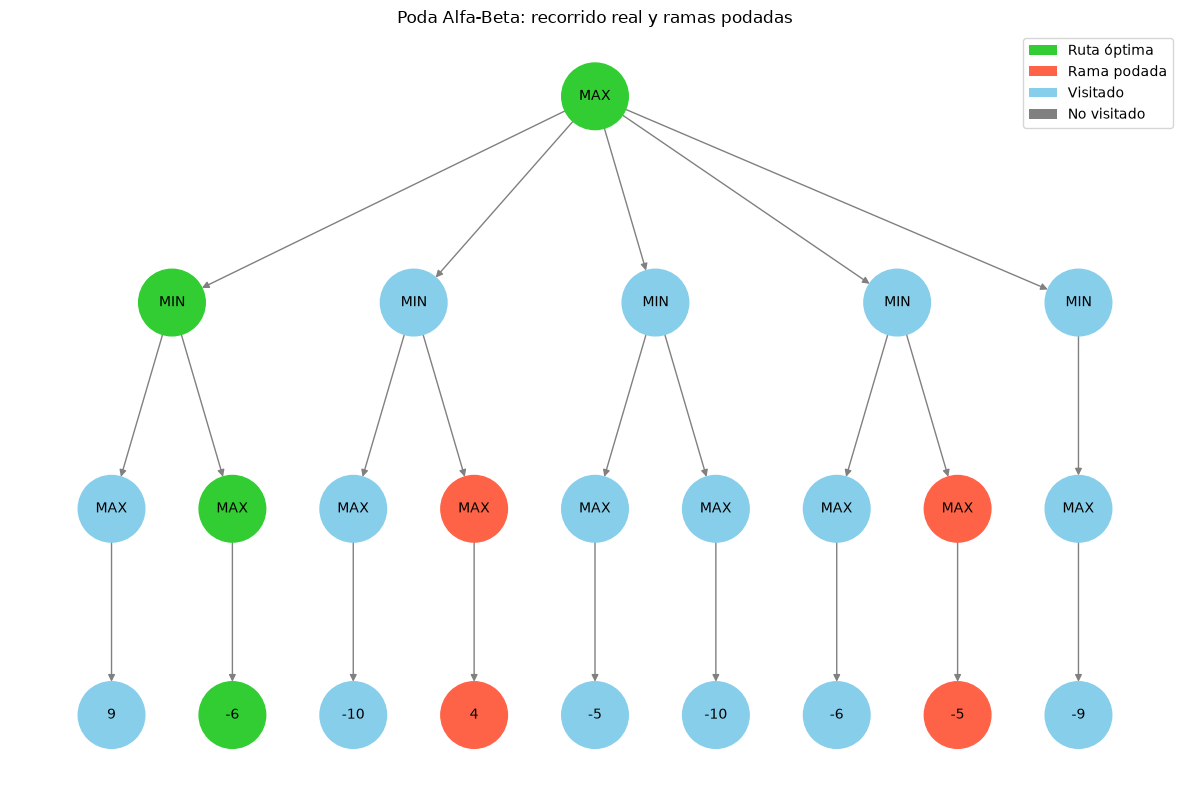

In [38]:
def is_leaf(node):
    return isinstance(node, (int, float))


def subtree_paths(node, path=()):
    """Devuelve todas las rutas del subárbol en orden DFS izquierda-derecha."""
    if is_leaf(node):
        return [path if path else ('root',)]

    paths = [path if path else ('root',)]
    for idx, child in enumerate(node):
        paths.extend(subtree_paths(child, path + (idx,)))
    return paths


def minimax_exact(node, depth=0):
    """Valor exacto minimax sin poda, útil para validación formal."""
    if is_leaf(node):
        return float(node), ()

    if depth % 2 == 0:  # MAX
        best_value = -float('inf')
        best_path = ()
        for idx, child in enumerate(node):
            child_value, child_path = minimax_exact(child, depth + 1)
            if child_value > best_value:
                best_value = child_value
                best_path = (idx,) + child_path
        return best_value, best_path

    best_value = float('inf')
    best_path = ()
    for idx, child in enumerate(node):
        child_value, child_path = minimax_exact(child, depth + 1)
        if child_value < best_value:
            best_value = child_value
            best_path = (idx,) + child_path
    return best_value, best_path


def alpha_beta(node, depth=0, alpha=-float('inf'), beta=float('inf'), path=()):
    """Evalúa con poda alfa-beta respetando un recorrido estrictamente DFS de izquierda a derecha."""
    node_id = path if path else ('root',)
    visited = {node_id}

    if is_leaf(node):
        return float(node), path, [], visited

    if depth % 2 == 0:  # MAX
        best_value = -float('inf')
        best_path = ()
        pruned = []

        for idx, child in enumerate(node):
            child_value, child_path, child_pruned, child_visited = alpha_beta(
                child, depth + 1, alpha, beta, path + (idx,)
            )
            visited |= child_visited
            pruned.extend(child_pruned)

            if child_value > best_value:
                best_value = child_value
                best_path = child_path

            alpha = max(alpha, best_value)
            if alpha >= beta:
                for right_idx in range(idx + 1, len(node)):
                    right_path = path + (right_idx,)
                    for p in subtree_paths(node[right_idx], right_path):
                        pruned.append({'node': p, 'reason': 'corte por beta'})
                break

        return best_value, best_path, pruned, visited

    # MIN
    best_value = float('inf')
    best_path = ()
    pruned = []

    for idx, child in enumerate(node):
        child_value, child_path, child_pruned, child_visited = alpha_beta(
            child, depth + 1, alpha, beta, path + (idx,)
        )
        visited |= child_visited
        pruned.extend(child_pruned)

        if child_value < best_value:
            best_value = child_value
            best_path = child_path

        beta = min(beta, best_value)
        if alpha >= beta:
            for right_idx in range(idx + 1, len(node)):
                right_path = path + (right_idx,)
                for p in subtree_paths(node[right_idx], right_path):
                    pruned.append({'node': p, 'reason': 'corte por alfa'})
            break

    return best_value, best_path, pruned, visited


def ordered_paths(node, path=()):
    """Recorrido DFS en profundidad de izquierda a derecha."""
    if is_leaf(node):
        yield path if path else ('root',)
        return

    yield path if path else ('root',)
    for idx, child in enumerate(node):
        yield from ordered_paths(child, path + (idx,))


def validate_alpha_beta(tree):
    """Comprueba que el valor y la ruta coinciden con el minimax exacto y que la poda respeta el orden DFS."""
    value, optimal_path, pruned_branches, visited_paths = alpha_beta(tree)
    exact_value, exact_path = minimax_exact(tree)

    if abs(value - exact_value) > 1e-9:
        raise AssertionError(f'Valor incorrecto: alpha-beta={value}, exacto={exact_value}')

    if tuple(optimal_path) != tuple(exact_path):
        raise AssertionError(f'Ruta óptima incorrecta: alpha-beta={optimal_path}, exacta={exact_path}')

    pruned_set = {item['node'] for item in pruned_branches}
    visited_set = {p for p in visited_paths if p != ('root',)}
    order = list(ordered_paths(tree))
    order_index = {p: i for i, p in enumerate(order)}

    for pruned in pruned_set:
        for visited in visited_set:
            if pruned != visited and order_index.get(pruned, -1) < order_index.get(visited, -1):
                raise AssertionError(
                    f'Violación de orden: nodo podado {pruned} aparece a la izquierda de un nodo visitado {visited}.'
                )

    print('Validación Alpha-Beta: OK')
    print(f'Valor exacto: {exact_value}')
    print(f'Ruta óptima exacta: {exact_path}')
    print(f'Ramas podadas: {pruned_branches}')
    return value, optimal_path, pruned_branches, visited_paths


def count_leaves(node):
    if is_leaf(node):
        return 1
    return sum(count_leaves(child) for child in node)


def build_tree_graph(tree, optimal_path=(), pruned_paths=(), visited_paths=()):
    G = nx.DiGraph()
    visited_set = {('root',) if p == () else p for p in visited_paths}
    pruned_set = {('root',) if p == () else p for p in pruned_paths}

    def graph_id(path=()):
        return ('root',) if path == () else path

    def collect_all_paths(node, path=()):
        all_paths.add(graph_id(path))
        if is_leaf(node):
            return
        for idx, child in enumerate(node):
            collect_all_paths(child, path + (idx,))

    all_paths = set()
    collect_all_paths(tree)

    optimal_prefixes = {graph_id(optimal_path[:i]) for i in range(1, len(optimal_path) + 1)}
    if optimal_path:
        optimal_prefixes.add(('root',))

    def add_node(node, path=()):
        node_id = graph_id(path)
        if is_leaf(node):
            G.add_node(node_id, depth=len(path), kind='leaf', label=str(node), display_label=str(node))
            return

        G.add_node(
            node_id,
            depth=len(path),
            kind='internal',
            label='MAX' if len(path) % 2 == 0 else 'MIN',
            display_label='MAX' if len(path) % 2 == 0 else 'MIN',
        )
        for idx, child in enumerate(node):
            child_id = graph_id(path + (idx,))
            G.add_edge(node_id, child_id)
            add_node(child, path + (idx,))

    add_node(tree)

    pos = {}

    def assign_positions(node, path=(), left=0.0, right=1.0, depth=0):
        node_id = graph_id(path)
        pos[node_id] = ((left + right) / 2, -depth)

        if is_leaf(node):
            return

        weights = [count_leaves(child) for child in node]
        total_weight = sum(weights)
        segment_width = right - left
        cursor = left

        for idx, child in enumerate(node):
            child_weight = weights[idx]
            if total_weight == 0:
                child_width = segment_width / len(node)
            else:
                child_width = (child_weight / total_weight) * segment_width

            child_left = cursor
            child_right = cursor + child_width
            assign_positions(child, path + (idx,), child_left, child_right, depth + 1)
            cursor = child_right

    assign_positions(tree)

    colors = []
    for node in G.nodes():
        if node in pruned_set:
            colors.append('tomato')
        elif node in optimal_prefixes:
            colors.append('limegreen')
        elif node in visited_set:
            colors.append('skyblue')
        else:
            colors.append('gray')

    return G, pos, colors


def mostrar_resultado(tree):
    valor, ruta_optima, ramas_podadas, nodos_visitados = alpha_beta(tree)
    pruned_paths = [item['node'] for item in ramas_podadas]
    visited_paths = [p for p in nodos_visitados if p != ('root',)]
    G, pos, colors = build_tree_graph(tree, ruta_optima, pruned_paths, visited_paths)

    print(f'Valor minimax con poda alfa-beta: {valor}')
    print(f'Ruta óptima de decisión: {ruta_optima}')
    print('Ramas podadas:')
    if not ramas_podadas:
        print('  Ninguna')
    else:
        for item in ramas_podadas:
            print(f"  - Nodo: {item['node']} | motivo: {item['reason']}")

    print('Nodos visitados:', sorted(visited_paths))

    fig, ax = plt.subplots(figsize=(12, 8))
    labels = {node: G.nodes[node]['display_label'] for node in G.nodes()}
    nx.draw(
        G,
        pos,
        with_labels=True,
        labels=labels,
        node_color=colors,
        node_size=2300,
        edge_color='gray',
        font_size=10,
        ax=ax,
    )

    legend_handles = [
        Patch(facecolor='limegreen', label='Ruta óptima'),
        Patch(facecolor='tomato', label='Rama podada'),
        Patch(facecolor='skyblue', label='Visitado'),
        Patch(facecolor='gray', label='No visitado'),
    ]
    ax.legend(handles=legend_handles, loc='upper right')
    ax.set_title('Poda Alfa-Beta: recorrido real y ramas podadas')
    plt.tight_layout()
    plt.show()

    return valor, ruta_optima, ramas_podadas

valor, ruta, podadas = mostrar_resultado(tree)